In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import pathlib as Path
import matplotlib.pyplot as plt

import hydro_model as hm
import hydro_plots as hp

print("numba available (fast runs):", hm.HAS_NUMBA)

numba available (fast runs): True


In [2]:
pip install numba

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 12.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 MB 24.9 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [numba]32m1/2 [numba]

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
# paths for catchment
folder = Path("/Users/emmaschima/Desktop/camels_ch/timeseries/observation_based/")
gauge_id = 2263
camels_file = folder / f"CAMELS_CH_obs_based_{gauge_id}.csv"
station_file = next(folder.glob("ogd-smn_sam_d_historical*.csv"))
assert camels_file.exists(), f"File not found: {camels_file}"

latitude = 46.4
Z_MIN, Z_MAX = 1661, 3224 # lowest and highest points of catchment m a.s.l.
Z_STATION = 1723 # station elevation
LAPSE = 0.006 # T lapse rate

col_P, col_Q = "precipitation(mm/d)", "discharge_spec(mm/d)"

TypeError: 'module' object is not callable

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import hydro_model as hm       # data, bands, model, metrics, calibration  (external file)
import hydro_plots as hp       # plotting functions                        (external file)

print("numba available (fast runs):", hm.HAS_NUMBA)   # if False: pip install numba -> ~100x faster

# paths for catchment
folder = Path("/Users/emmaschima/Desktop/camels_ch/timeseries/observation_based/")
gauge_id = 2263                                      # Chamuerabach
camels_file  = folder / f"CAMELS_CH_obs_based_{gauge_id}.csv"
station_file = next(folder.glob("ogd-smn_sam_d_historical*.csv"))   # Samedan
assert camels_file.exists(), f"File not found: {camels_file}"

latitude  = 46.6
Z_MIN, Z_MAX = 1661, 3224        # lowest and highest point of the catchment m a.s.l.
Z_STATION    = 1723              # station (m a.s.l.)
LAPSE        = 0.006             # T lapse rate

col_P, col_Q = "precipitation(mm/d)", "discharge_spec(mm/d)"

# periods
# Warm-up: 2 years to fill the storages. Calibration and validation are SPLIT-SAMPLE:
# Widen CALIB to 1983-2009
SIM_START = "1997-01-01"
PERIODS = {"warm-up":     ("1997-01-01", "1998-12-31"),
           "calibration": ("1999-01-01", "2009-12-31"),
           "validation":  ("2010-01-01", "2020-12-31")}

# optimiser effort (differential evolution). Raise for a more thorough search.
CAL = dict(maxiter=20, popsize=6)

numba available (fast runs): True


In [7]:
# load data
df = hm.load_camels(camels_file).loc[SIM_START: "2020-12-31"]
P_station = hm.load_station_precip(station_file)

print("CAMELS period:", df.index.min().date(), "to", df.index.max().date())
print("Missing values per column:\n", df.isna().sum()[[col_P, col_Q, "temperature_mean(degC)"]])

obs = df[col_Q].values
idx = df.index
masks = {name: (idx >= a) & (idx <= b) for name, (a,b) in PERIODS.items()} # boolean

CAMELS period: 1997-01-01 to 2020-12-31
Missing values per column:
 precipitation(mm/d)       0
discharge_spec(mm/d)      0
temperature_mean(degC)    0
dtype: int64


Band mean elevations H_i (m): [1817. 2130. 2442. 2755. 3068.] | reference elevation: 2442
CAMELS / station P = 1.42  ->  gamma ~ 0.058 % per m (58.2 % per 100 m)   [calibration range: 0 - 0.1 % per m]


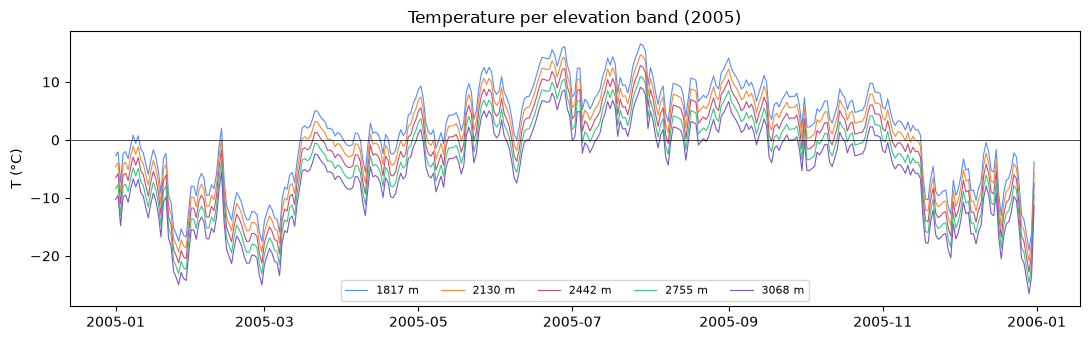

In [8]:
# elevation bands and precip gradient: catchment range 1661-3224 m, CAMELS uses catchment mean T and P. Splits catchment into equal area elevation bands
# 𝑇𝑖(𝑡) = 𝑇ref(𝑡)-β(𝐻i - Href), β = 0.006
# precip linear gradient, normalized so area-weighted mean precip is unchange (redistributes H2O does not add)
# results area-weighted (mm/d)
bands5 = hm.make_bands(Z_MIN, Z_MAX, 5)
print("Band mean elevations H_i (m):", bands5["H"].round(0), "| reference elevation:", round(bands5["z_ref"]))

# first guess of the precipitation gradient from station vs catchment precipitation
both = pd.concat([df[col_P], P_station], axis=1, join="inner").dropna()
ratio = both.iloc[:, 0].sum() / both.iloc[:, 1].sum()
gamma_est = (ratio - 1) / (bands5["z_ref"] - Z_STATION)
print(f"CAMELS / station P = {ratio:.2f}  ->  gamma ~ {gamma_est*100:.3f} % per m "
      f"({gamma_est*1e5:.1f} % per 100 m)   [calibration range: 0 - 0.1 % per m]")

# illustrate the bands: temperature per band for one year
fb = hm.build_forcing(df, bands5, latitude, lapse=LAPSE)
fig, ax = plt.subplots(figsize=(11, 3.5))
for j, h in enumerate(bands5["H"]):
    ax.plot(idx[idx.year == 2005], fb["T"][idx.year == 2005, j], lw=0.8, label=f"{h:.0f} m")
ax.axhline(0, color="k", lw=0.5); ax.set_ylabel("T (°C)"); ax.legend(ncol=5, fontsize=8)
ax.set_title("Temperature per elevation band (2005)")
plt.tight_layout(); plt.savefig("fig_bands_T.png", dpi=150); plt.show()

In [9]:
# make sure water balance is closed
# Σ P in - Σ ET - Σ Q = S end - S start (S = SWE + S soil + S ground + S quick)
# P in w/ snow correction factor
f1 = hm.build_forcing(df, hm.make_bands(Z_MIN, Z_MAX, 1), latitude, lapse=LAPSE)       # lumped
test_params = dict(k_s=0.05, S_max=300, DDF=4.0, SCF=1.2, I_thr=1.0)
opt_test = dict(n_slow=1, quick=False)

print(f"{'version':22s} {'P_in':>8s} {'ET':>7s} {'Q':>8s} {'dS':>7s} {'P-ET-Q-dS':>10s}")
for label, leak in [("old Ex.3 (leaky)", True), ("fixed", False)]:
    res = hm.run_model(f1, test_params, dict(opt_test, leak=leak))
    wb = hm.water_balance(res, masks["calibration"] | masks["validation"])
    print(f"{label:22s} {wb['P']:8.1f} {wb['ET']:7.1f} {wb['Q']:8.1f} {wb['dStorage']:7.1f} {wb['residual_naive']:10.3f}")

version                    P_in      ET        Q      dS  P-ET-Q-dS
old Ex.3 (leaky)        24575.4  3779.7  20751.7    26.7     17.216
fixed                   24575.4  3779.9  20768.7    26.7     -0.000


In [10]:
# model and elevation bands, each calibration on calibration pd
# A1 = 1 storage (soil box), no overland flow, 1 band (lumped)
# A2 = 2 storage (soil box + groundwater), no overland flow, 1 band
# A3 = 3 storage (adds quick reservoir), overland flow, 1 band
# B1 = same storage as A3, overland flow, 5 bands
# B2 = same storage as A3, overland flow, 10 bands

experiments = {
    "A1: 1 storage":          (1,  dict(n_slow=1, quick=False)),
    "A2: 2 storages":         (1,  dict(n_slow=2, quick=False)),
    "A3: 2 storages + quick": (1,  dict(n_slow=2, quick=True)),
    "B1: A3 + 5 bands":       (5,  dict(n_slow=2, quick=True)),
    "B2: A3 + 10 bands":      (10, dict(n_slow=2, quick=True)),
}

results = {}
for name, (n_b, opt) in experiments.items():
    results[name] = hm.run_experiment(name, df, Z_MIN, Z_MAX, n_b, opt, latitude, obs, masks,
                                      lapse=LAPSE, **CAL)

table = pd.concat([r["metrics"] for r in results.values()]).set_index(["experiment", "period"])
print(table.round(2).to_string())

[A1: 1 storage]  bands = 1, options = {'n_slow': 1, 'quick': False}
  best score 0.647 after 756 runs: {'S_max': 762.0713, 'DDF': 5.0843, 'T_snow': -1.4623, 'SCF': 1.1841, 'k_s': 0.0155, 'I_thr': 1.4566}
[A2: 2 storages]  bands = 1, options = {'n_slow': 2, 'quick': False}
  best score 0.648 after 882 runs: {'S_max': 129.4953, 'DDF': 7.9442, 'T_snow': -1.4289, 'SCF': 1.2414, 'k_s': 0.4223, 'k_g': 0.0166, 'I_thr': 2.1069}
[A3: 2 storages + quick]  bands = 1, options = {'n_slow': 2, 'quick': True}
  best score 0.678 after 1008 runs: {'S_max': 63.2282, 'DDF': 7.7599, 'T_snow': -1.2572, 'SCF': 1.1695, 'k_s': 0.4573, 'k_g': 0.0147, 'k_fast': 0.0616, 'I_thr': 1.7936}
[B1: A3 + 5 bands]  bands = 5, options = {'n_slow': 2, 'quick': True}
  best score 0.871 after 1134 runs: {'S_max': 54.9815, 'DDF': 5.9793, 'T_snow': 1.6528, 'SCF': 1.1344, 'k_s': 0.07, 'k_g': 0.005, 'k_fast': 0.0867, 'I_thr': 2.1947, 'gamma': 0.0001}
[B2: A3 + 10 bands]  bands = 10, options = {'n_slow': 2, 'quick': True}
  best 

A1: 1 storage             residual = 4.5e-12 mm   (P = 23786 mm, Q = 18722 mm)
A2: 2 storages            residual = 4.8e-12 mm   (P = 24230 mm, Q = 20809 mm)
A3: 2 storages + quick    residual = 5.7e-12 mm   (P = 23716 mm, Q = 20285 mm)
B1: A3 + 5 bands          residual = -5.0e-12 mm   (P = 23980 mm, Q = 19085 mm)
B2: A3 + 10 bands         residual = 3.5e-12 mm   (P = 23861 mm, Q = 19118 mm)


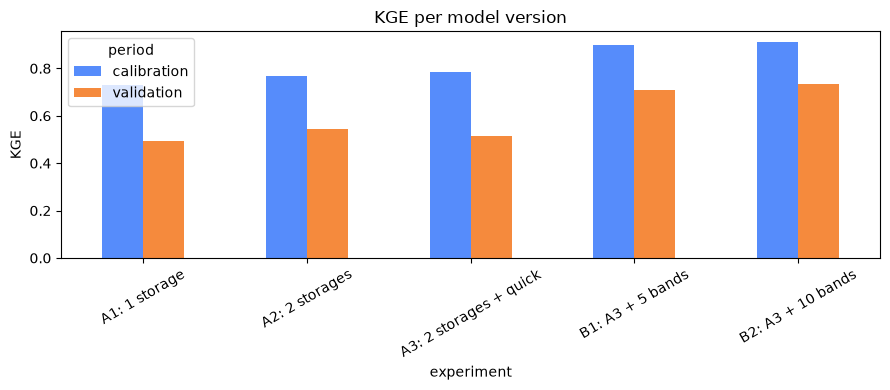

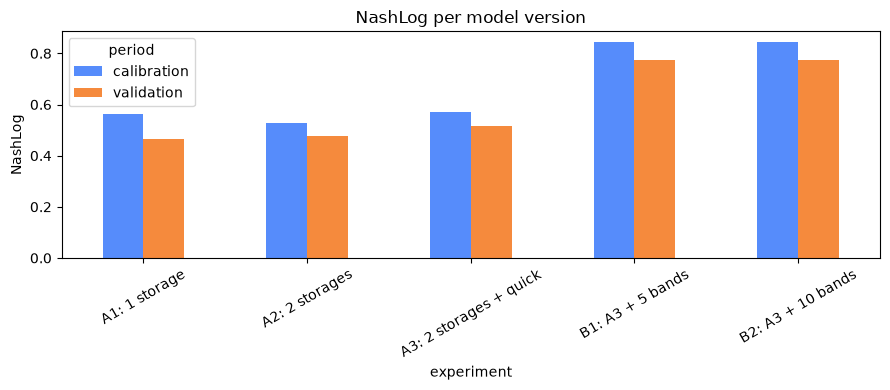

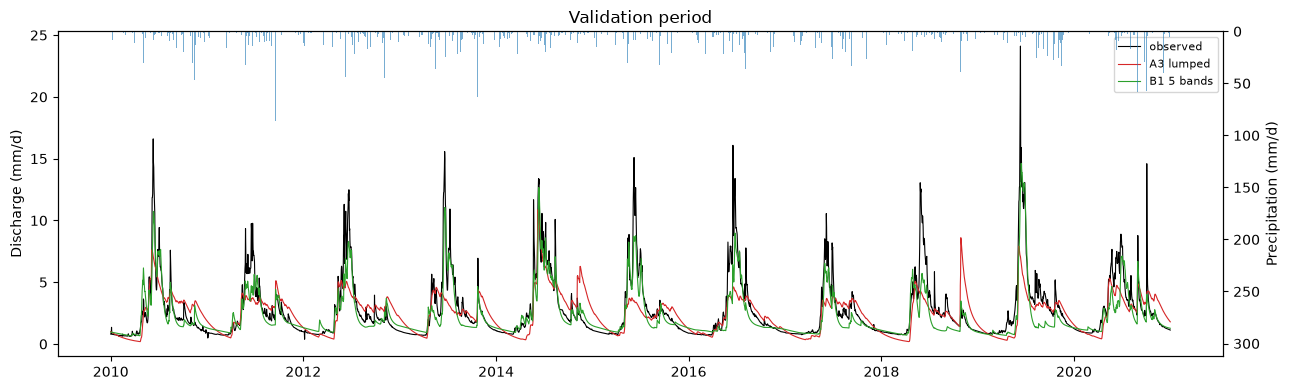

In [11]:
# water balance close for all versions
for name, r in results.items():
    wb = hm.water_balance(r["res"], ~masks["warm-up"])
    print(f"{name:25s} residual = {wb['residual']:.1e} mm   (P = {wb['P']:.0f} mm, Q = {wb['Q']:.0f} mm)")
    assert abs(wb["residual"]) < 1e-6, "water balance does not close!"

hp.plot_comparison(table, "KGE", fname="fig_cmp_kge.png")
hp.plot_comparison(table, "NashLog", fname="fig_cmp_nashlog.png")

# hydrographs of the validation period: lumped best vs banded
v = masks["validation"]
fig, ax = plt.subplots(figsize=(13, 4))
hp.plot_hydrograph(ax, idx[v], obs[v],
                   {"A3 lumped": results["A3: 2 storages + quick"]["res"]["Q"][v],
                    "B1 5 bands": results["B1: A3 + 5 bands"]["res"]["Q"][v]},
                   P=results["B1: A3 + 5 bands"]["forcing"]["P"][v], title="Validation period")
plt.tight_layout(); plt.savefig("fig_structure_hydro.png", dpi=150); plt.show()

Final parameters: {'S_max': 54.9815, 'DDF': 5.9793, 'T_snow': 1.6528, 'SCF': 1.1344, 'k_s': 0.07, 'k_g': 0.005, 'k_fast': 0.0867, 'I_thr': 2.1947, 'gamma': 0.0001}
              KGE    NSE  NashLog   Bias      r  alpha   beta
period                                                       
calibration  0.90  0.799    0.843  -0.30  0.901  1.014  0.997
validation   0.71  0.770    0.776 -15.29  0.902  0.773  0.847


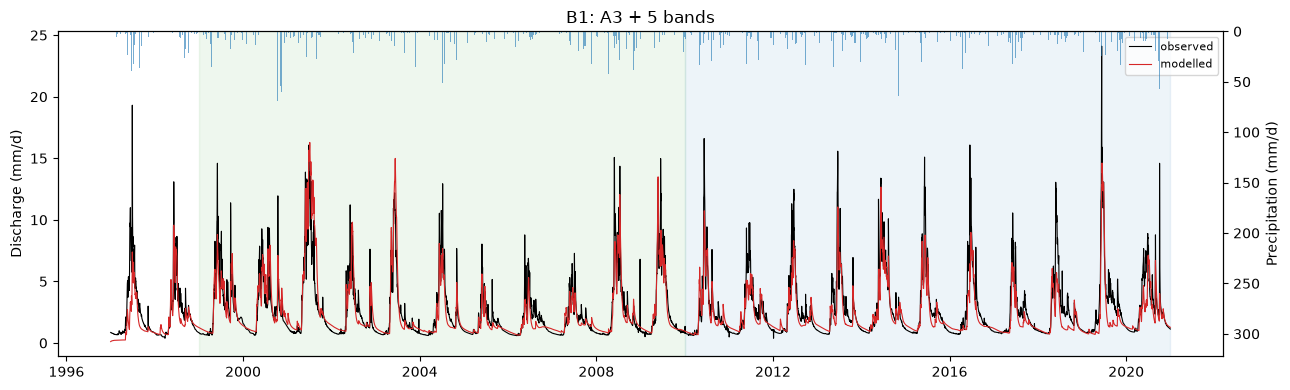

In [12]:
# final model
FINAL = "B1: A3 + 5 bands"
fin = results[FINAL]
q_fin = fin["res"]["Q"]
print("Final parameters:", {k: round(v, 4) for k, v in fin["params"].items()})
print(table.loc[FINAL].round(3).to_string())

fig, ax = plt.subplots(figsize=(13, 4))
hp.plot_hydrograph(ax, idx, obs, {"modelled": q_fin}, P=fin["forcing"]["P"], title=FINAL)
for name, c in [("calibration", "tab:green"), ("validation", "tab:blue")]:
    a, b = PERIODS[name]; ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=c, alpha=0.08)
plt.tight_layout(); plt.savefig("fig_final_hydro.png", dpi=150); plt.show()

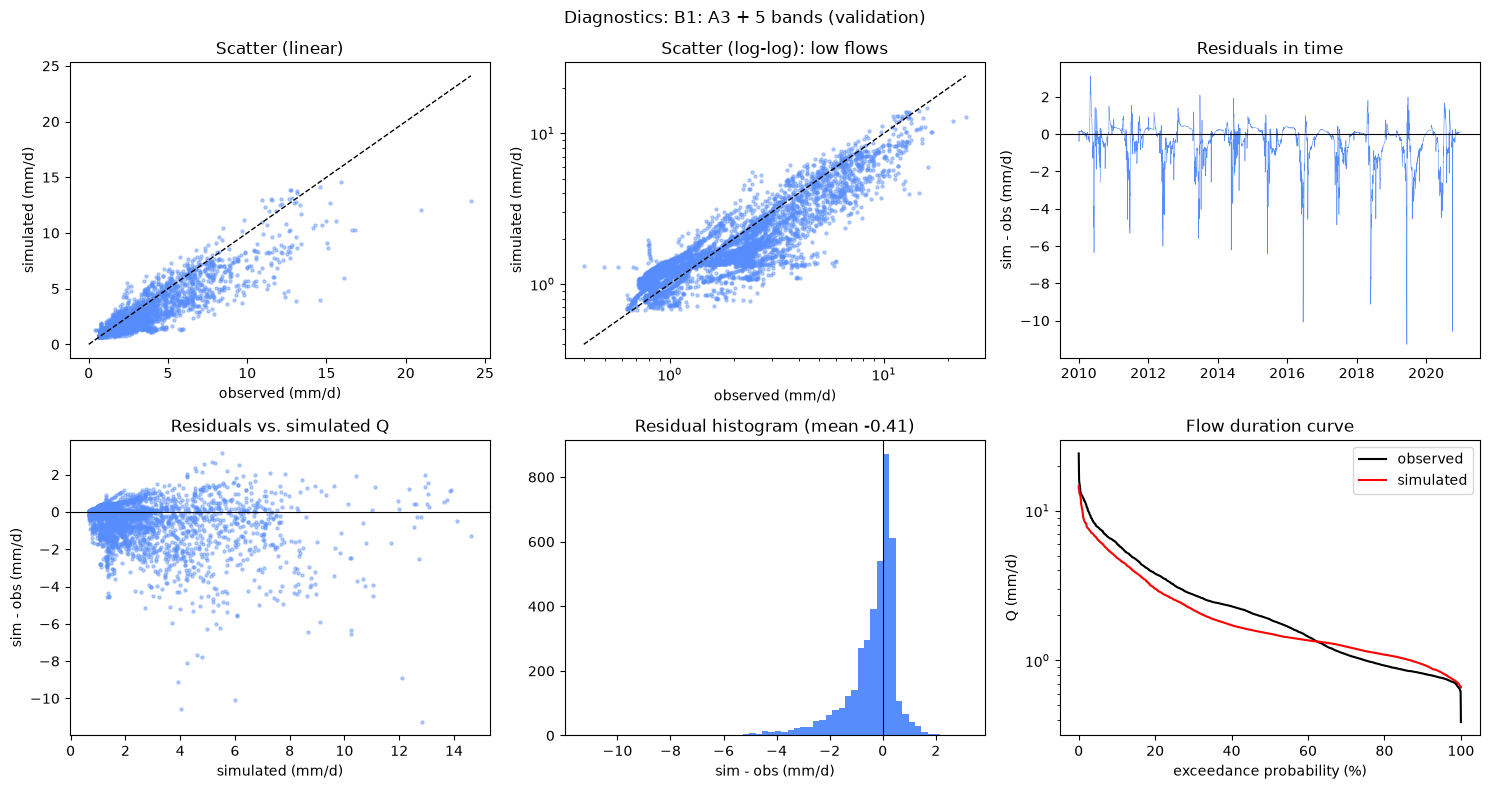

In [13]:
# diagnostic plots (validation period): scatter, residuals, flow duration curve
v = masks["validation"]
hp.plot_diagnostics(idx[v], obs[v], q_fin[v], name=FINAL + " (validation)", fname="fig_diagnostics.png")

Good window ends: 2011-11-02 | bad window ends: 2018-07-05


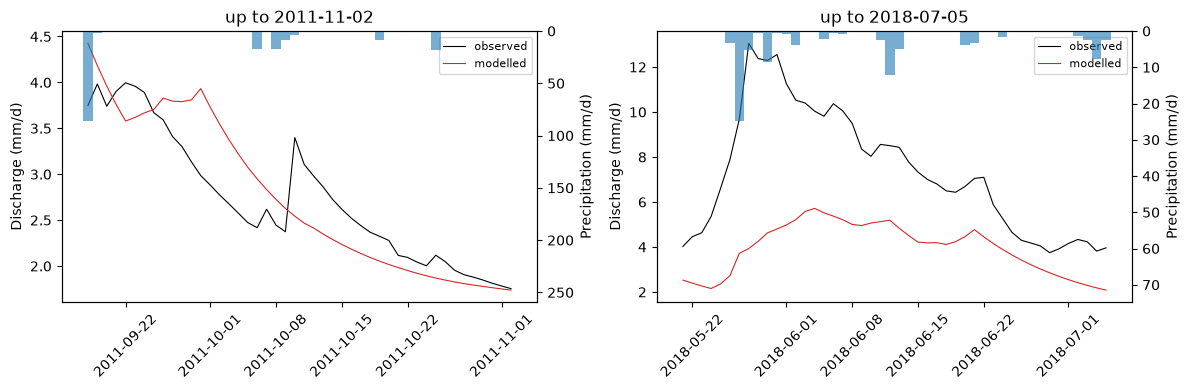

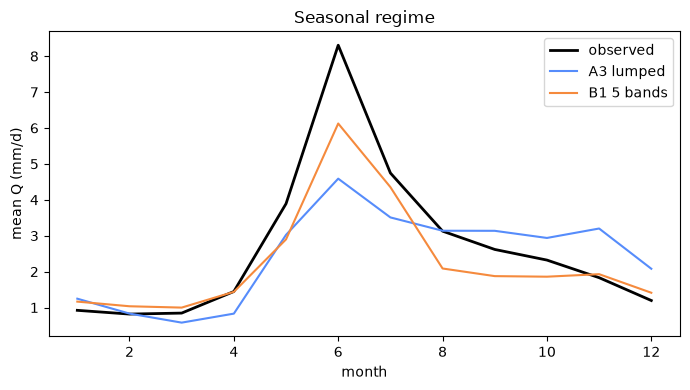

In [14]:
# individual events (best / worst 45-day high-flow window) and seasonal regime
hp.plot_events(idx[v], obs[v], q_fin[v], fin["forcing"]["P"][v], fname="fig_events.png")
hp.plot_regime(idx[v], obs[v], {"A3 lumped": results["A3: 2 storages + quick"]["res"]["Q"][v],
                                "B1 5 bands": q_fin[v]}, fname="fig_regime.png")

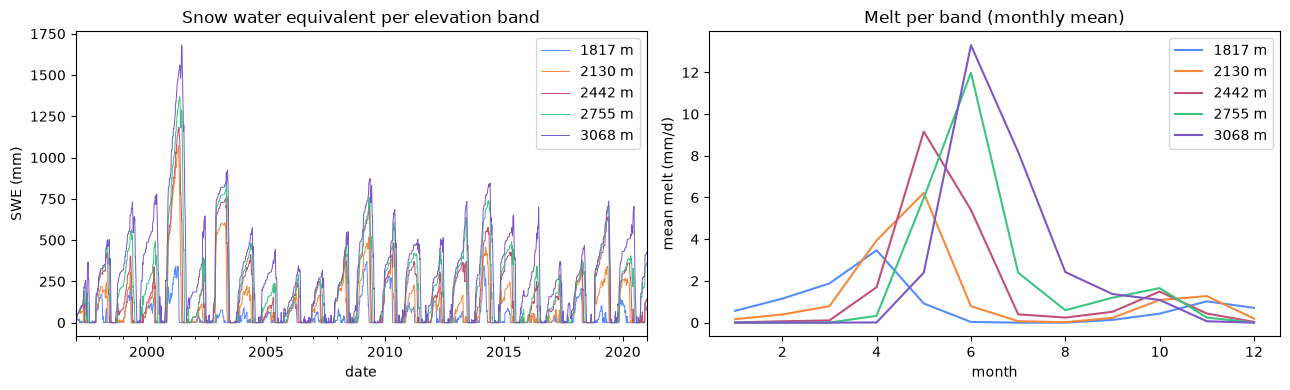

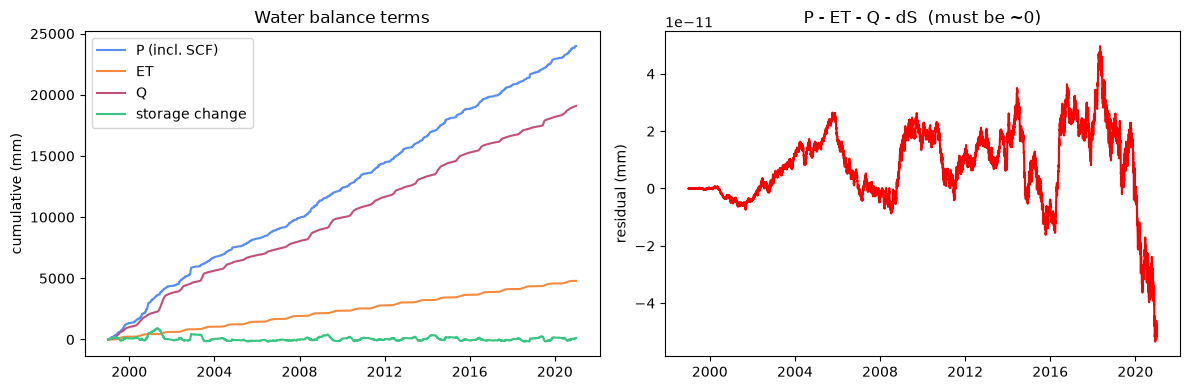

{'P': np.float64(23980.052490637274), 'ET': np.float64(4786.806253404535), 'Q': np.float64(19084.694083147788), 'lost': np.float64(0.0), 'dStorage': np.float64(108.55215408495633), 'residual': np.float64(-5.002220859751105e-12), 'residual_naive': np.float64(-5.002220859751105e-12)}


In [15]:
# snow per elevation band, and water balance of the final model
hp.plot_bands(fin["res"], fin["forcing"], fname="fig_bands_swe.png")
hp.plot_water_balance(fin["res"], ~masks["warm-up"], idx, fname="fig_water_balance.png")
print(hm.water_balance(fin["res"], ~masks["warm-up"]))